# Cobalt Grid: LoRA-rank ablation for day-ahead demand forecasting

Runs the whole study in one free-tier Colab GPU session (~30 min on a T4). Every cell calls a script from the
repository; open the `.py` files to see the logic.

**Before you start:** *Runtime → Change runtime type → T4 GPU*. Then *Runtime → Run all*.
If the session disconnects during stage 3, re-run from the top; finished runs are kept and skipped.

In [1]:
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv

name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07


In [2]:
import os
REPO_URL = "https://github.com/nmilleson/csp-cst627-week7.git"
if not os.path.exists("csp-cst627-week7"):
    !git clone -q $REPO_URL
%cd /content/csp-cst627-week7
!git log -1 --format="commit %h  %s"
!pip install -q -r requirements-colab.txt
!python -c "import torch; print('torch', torch.__version__, '| CUDA available:', torch.cuda.is_available())"

/content/csp-cst627-week7
commit b564b72  Add reproducible LoRA-rank ablation for day-ahead demand forecasting
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.2 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.2 which is incompatible.
numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.4.2 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.2 which is incompatible.
torch 2.11.0+cu130 | CUDA available: True


In [3]:
CONFIG = "configs/ablation.yaml"      # "configs/smoke.yaml" = 2-minute dry run of the same pipeline
RESULTS = "results_smoke" if "smoke" in CONFIG else "results"

from IPython.display import Image, Markdown, display
def show(name, width=950):
    display(Image(filename=f"{RESULTS}/{name}", width=width))

## 1 · Data: synthetic co-op demand (seeded, hashed)
24 source co-ops (US + Central EU) for pretraining; one Nordic target co-op with heat pumps and EV charging.
A rerun prints `MATCH` when the files are byte-identical to the recorded manifest.

wrote data/source_coops.csv.gz  rows=631,296  sha256=75a0099458e2cdeb
wrote data/target_coop.csv.gz  rows=26,304  sha256=8d73955277cf4177
Reproducibility check vs previous manifest: MISMATCH
config 6e2e71d9b599  done in 11.0s


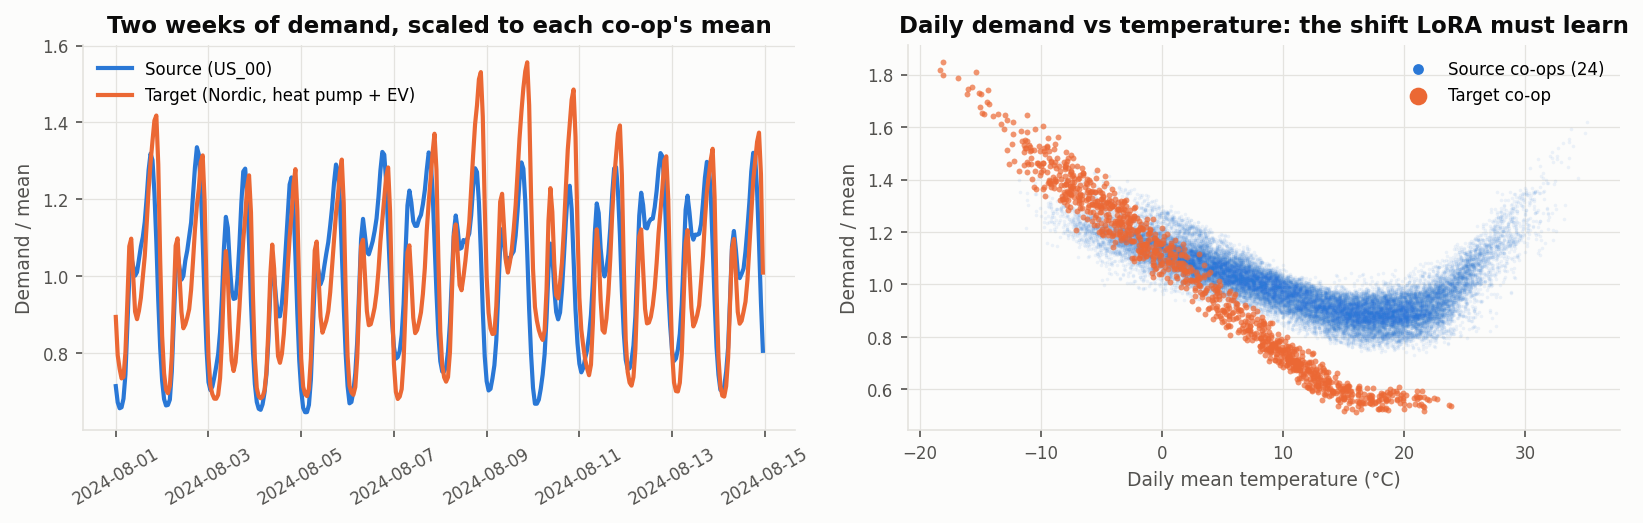

In [4]:
!python scripts/01_make_data.py --config $CONFIG
show("fig_data_overview.png")

## 2 · Pretrain the shared base model (fixed seed, run once)

In [5]:
!python scripts/02_pretrain.py --config $CONFIG

device: cuda  config: 6e2e71d9b599
source series=24  train windows=503,448  val windows=5,784
/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
  step   250  train 0.1911  val 0.0514
  step   500  train 0.0319  val 0.0303
  step   750  train 0.0223  val 0.0271
  step  1000  train 0.0200  val 0.0234
  step  1250  train 0.0180  val 0.0225
  step  1500  train 0.0169  val 0.0201
  step  1750  train 0.0161  val 0.0205
  step  2000  train 0.0152  val 0.0192
  step  2250  train 0.0148  val 0.0177
  step  2500  train 0.0140  val 0.0172
  step  2750  train 0.0138  val 0.0164
  step  3000  train 0.0

## 3 · Ablation: LoRA rank × seed (+ zero-shot and full fine-tune brackets)
One line per run: accuracy, wall-clock, peak GPU memory and latency. Resumable.

In [6]:
!python scripts/03_run_ablation.py --config $CONFIG

device cuda  config 6e2e71d9b599  target windows: train=1969  val=313  test=697
[1/36] zero_shot  seed=0
    MAPE 2.616%  MAE 1.952 MW  params 0  train 0.0s  peak nan MiB  lat(b1) 5.82 ms
[2/36] full_ft  seed=0
/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
    MAPE 1.912%  MAE 1.382 MW  params 556,289  train 62.3s  peak 696 MiB  lat(b1) 6.18 ms
[3/36] lora_r1  seed=0
    MAPE 1.703%  MAE 1.228 MW  params 7,168  train 71.7s  peak 672 MiB  lat(b1) 11.08 ms
[4/36] lora_r2  seed=0
    MAPE 1.758%  MAE 1.262 MW  params 14,336  train 74.7s  peak 674 MiB  lat(b1) 11.84 ms
[5/36] lora_r4  seed

## 4 · Analysis: means, seed spread, and whether rank beats noise

In [7]:
!python scripts/04_analyze.py --config $CONFIG > /dev/null
display(Markdown(open(f"{RESULTS}/summary.md", encoding="utf-8").read()))

## Accuracy (test split, 30 days, hourly forecast origins)

| Setting | Seeds | Trainable params | Adapter (KiB) | Test MAPE % (mean ± SD [95% CI]) | MAE (MW) | RMSE (MW) | Peak err % |
|---|---|---|---|---|---|---|---|
| Zero-shot | 1 | 0 | 0.0 | 2.616 | 1.952 | 2.566 | 1.916 |
| LoRA r=1 | 5 | 7,168 | 28.0 | 1.784 ± 0.061 [±0.076] | 1.285 ± 0.042 | 1.765 ± 0.062 | 1.398 ± 0.044 |
| LoRA r=2 | 5 | 14,336 | 56.0 | 1.797 ± 0.043 [±0.053] | 1.294 ± 0.026 | 1.784 ± 0.030 | 1.358 ± 0.020 |
| LoRA r=4 | 5 | 28,672 | 112.0 | 1.876 ± 0.044 [±0.054] | 1.343 ± 0.023 | 1.825 ± 0.019 | 1.359 ± 0.060 |
| LoRA r=8 | 5 | 57,344 | 224.0 | 2.099 ± 0.070 [±0.086] | 1.504 ± 0.051 | 1.998 ± 0.060 | 1.504 ± 0.108 |
| LoRA r=16 | 5 | 114,688 | 448.0 | 2.190 ± 0.110 [±0.136] | 1.566 ± 0.074 | 2.067 ± 0.094 | 1.500 ± 0.164 |
| LoRA r=32 | 5 | 229,376 | 896.0 | 2.216 ± 0.157 [±0.195] | 1.581 ± 0.105 | 2.059 ± 0.141 | 1.578 ± 0.130 |
| Full FT | 5 | 556,289 | 2173.0 | 2.005 ± 0.076 [±0.094] | 1.438 ± 0.046 | 1.949 ± 0.043 | 1.376 ± 0.022 |

## Cost

| Setting | Fine-tune time (s) | Peak GPU mem (MiB) | Mem above resident data (MiB) | Latency b1 (ms) | Latency b1 merged (ms) | Latency b256 (ms) | Latency b256 merged (ms) |
|---|---|---|---|---|---|---|---|
| Zero-shot | 0.0 | nan | nan | 5.82 | 5.85 | 42.85 | 42.99 |
| LoRA r=1 | 71.6 ± 0.1 | 671.9 ± 0.0 | 653.3 ± 0.0 | 11.32 ± 0.52 | 6.36 ± 0.14 | 64.07 ± 0.16 | 43.44 ± 0.15 |
| LoRA r=2 | 74.7 ± 0.1 | 674.1 ± 0.0 | 655.6 ± 0.0 | 11.39 ± 0.43 | 6.21 ± 0.20 | 66.93 ± 0.11 | 43.46 ± 0.10 |
| LoRA r=4 | 74.9 ± 0.1 | 678.7 ± 0.0 | 660.1 ± 0.0 | 11.53 ± 0.36 | 6.30 ± 0.28 | 67.06 ± 0.21 | 43.42 ± 0.15 |
| LoRA r=8 | 75.3 ± 0.1 | 687.7 ± 0.0 | 669.2 ± 0.0 | 11.49 ± 0.26 | 6.08 ± 0.26 | 67.64 ± 0.12 | 43.40 ± 0.07 |
| LoRA r=16 | 75.5 ± 0.1 | 706.4 ± 0.0 | 687.8 ± 0.0 | 11.31 ± 0.56 | 6.22 ± 0.17 | 68.60 ± 0.17 | 43.33 ± 0.14 |
| LoRA r=32 | 77.3 ± 0.1 | 742.1 ± 0.0 | 723.6 ± 0.0 | 11.54 ± 0.62 | 6.37 ± 0.27 | 70.48 ± 0.10 | 43.43 ± 0.09 |
| Full FT | 62.2 ± 0.1 | 696.3 ± 0.0 | 677.8 ± 0.0 | 6.16 ± 0.33 | 6.12 ± 0.24 | 43.49 ± 0.10 | 43.47 ± 0.14 |

## Each arm vs the best LoRA rank

| Arm | vs | Δ mean (pp) | Pooled seed SD | Cohen's d | > k·SD? | Welch p | Holm p | Verdict |
|---|---|---|---|---|---|---|---|---|
| Zero-shot | LoRA r=1 | +0.832 | 0.061 | +13.58 | yes | 7e-06 | 4.9e-05 | distinguishable |
| LoRA r=2 | LoRA r=1 | +0.013 | 0.053 | +0.25 | no | 0.709 | 0.709 | within noise |
| LoRA r=4 | LoRA r=1 | +0.091 | 0.053 | +1.71 | no | 0.0293 | 0.0586 | within noise |
| LoRA r=8 | LoRA r=1 | +0.315 | 0.066 | +4.81 | yes | 6.87e-05 | 0.000412 | distinguishable |
| LoRA r=16 | LoRA r=1 | +0.405 | 0.089 | +4.56 | yes | 0.000292 | 0.00146 | distinguishable |
| LoRA r=32 | LoRA r=1 | +0.432 | 0.119 | +3.62 | yes | 0.00202 | 0.00607 | distinguishable |
| Full FT | LoRA r=1 | +0.221 | 0.069 | +3.21 | yes | 0.00108 | 0.00434 | distinguishable |

## Verdict

**Question:** does LoRA rank (r ∈ {1, 2, 4, 8, 16, 32}) change day-ahead accuracy on the target co-op by more than run-to-run (seed) noise?

**Answer: yes** — rank has a measurable effect: the spread of rank means (0.432 pp MAPE) is larger than 2× the median seed SD (0.065 pp) and one-way ANOVA p = 1.37e-08.

- Best mean LoRA arm: **LoRA r=1** at 1.784 ± 0.061% MAPE.
- 3 of 5 other ranks are distinguishable from it (Holm-adjusted Welch p < 0.05 *and* |Δ| > 2× pooled seed SD).
- Trend in log2(rank): slope +0.102 pp per doubling (p = 1.79e-10).
- Adaptation itself matters: zero-shot base model = 2.616% MAPE (Δ +0.832 pp vs best LoRA).
- Full fine-tuning = 2.005 ± 0.076% MAPE with 556,289 trainable params vs 7,168 for LoRA r=1.
- Smallest adapter (LoRA r=1) stores 28.0 KiB per co-op; once merged, adapters add no inference compute at any rank (merged latency matches the base model within timing noise).


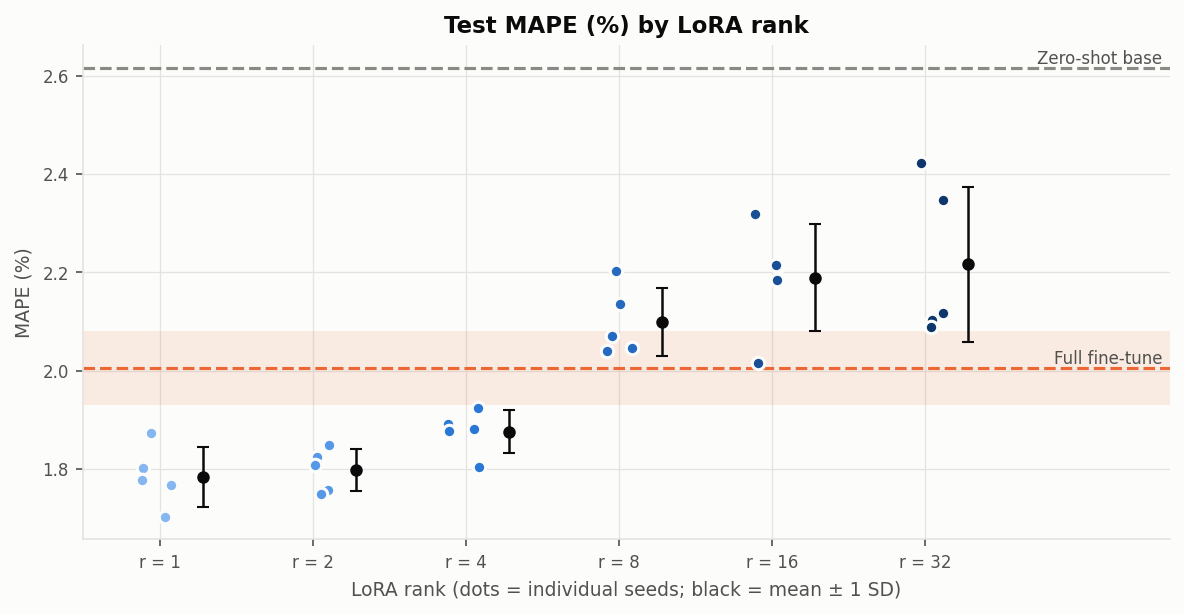

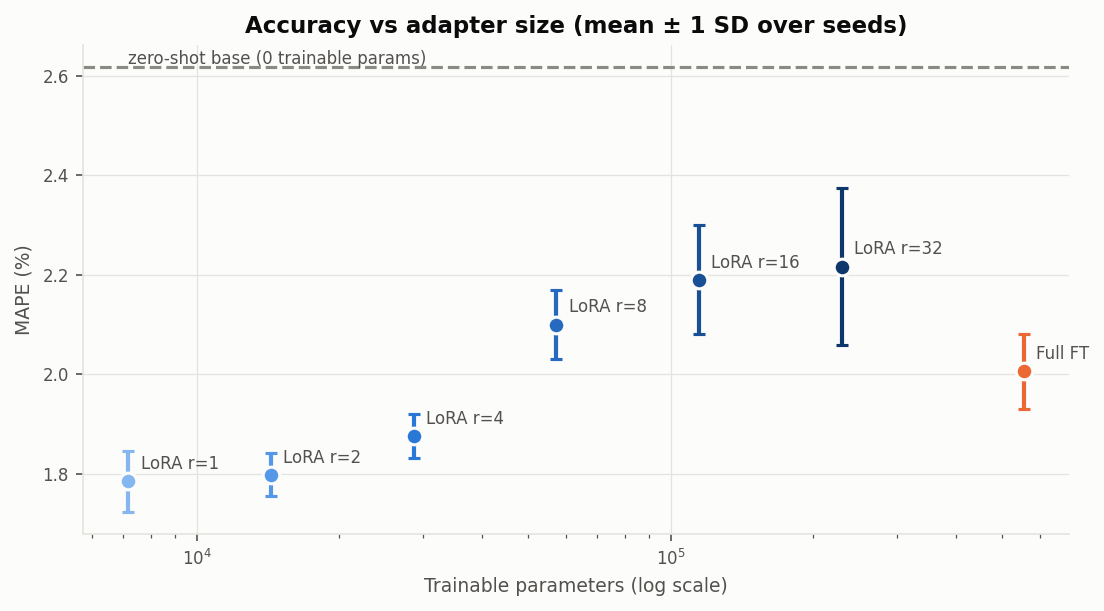

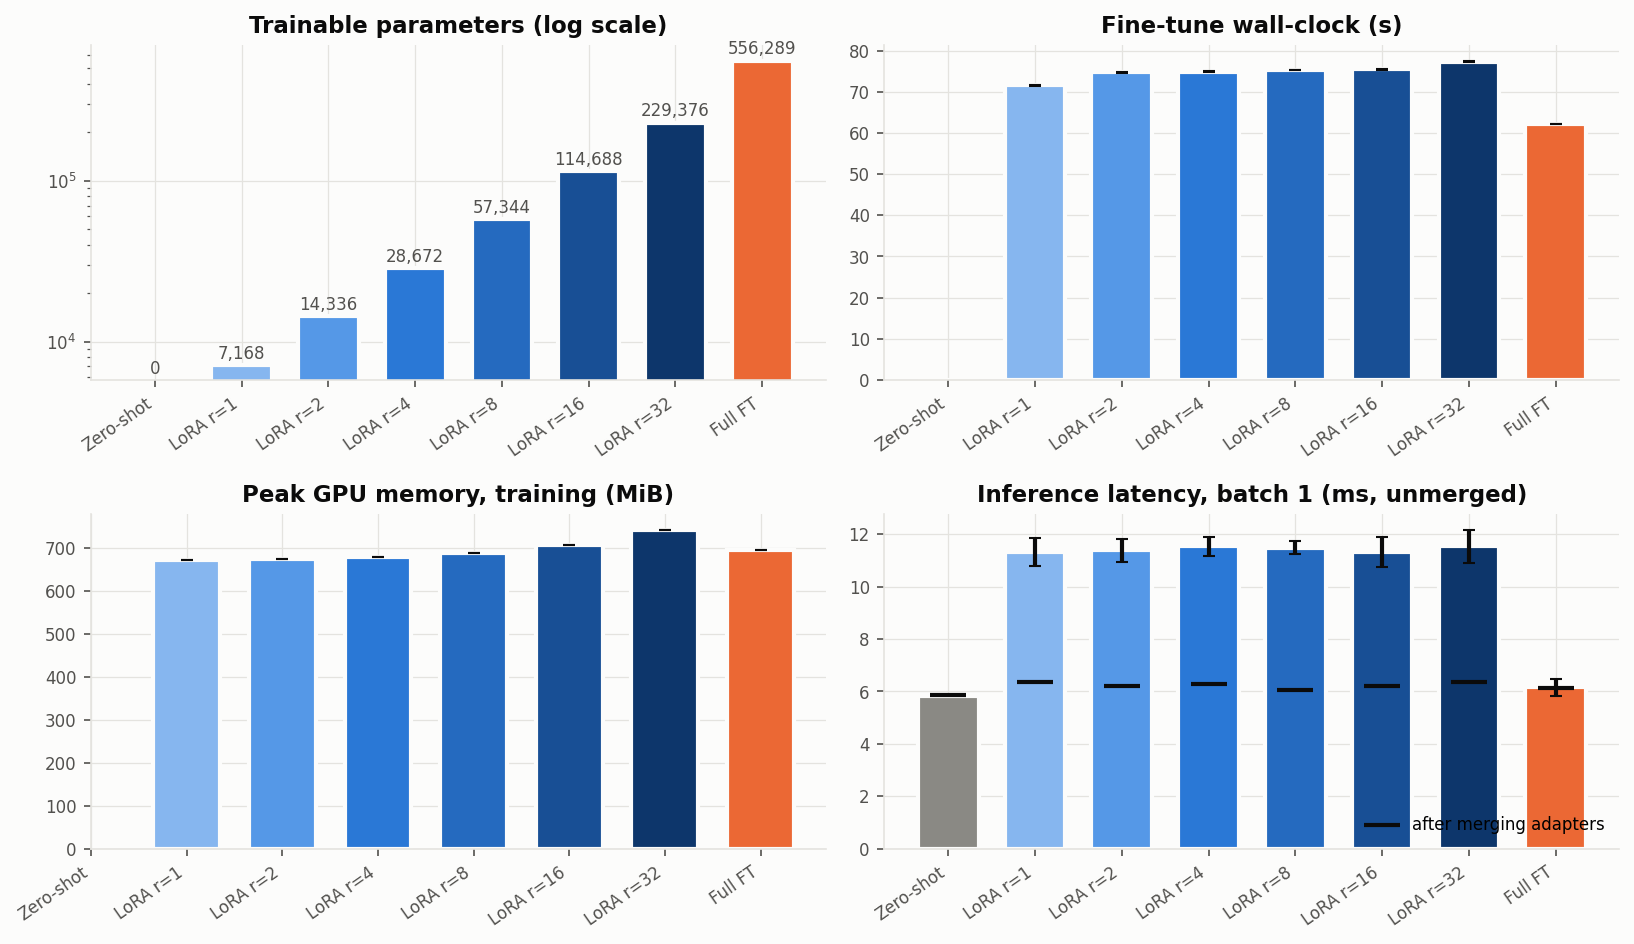

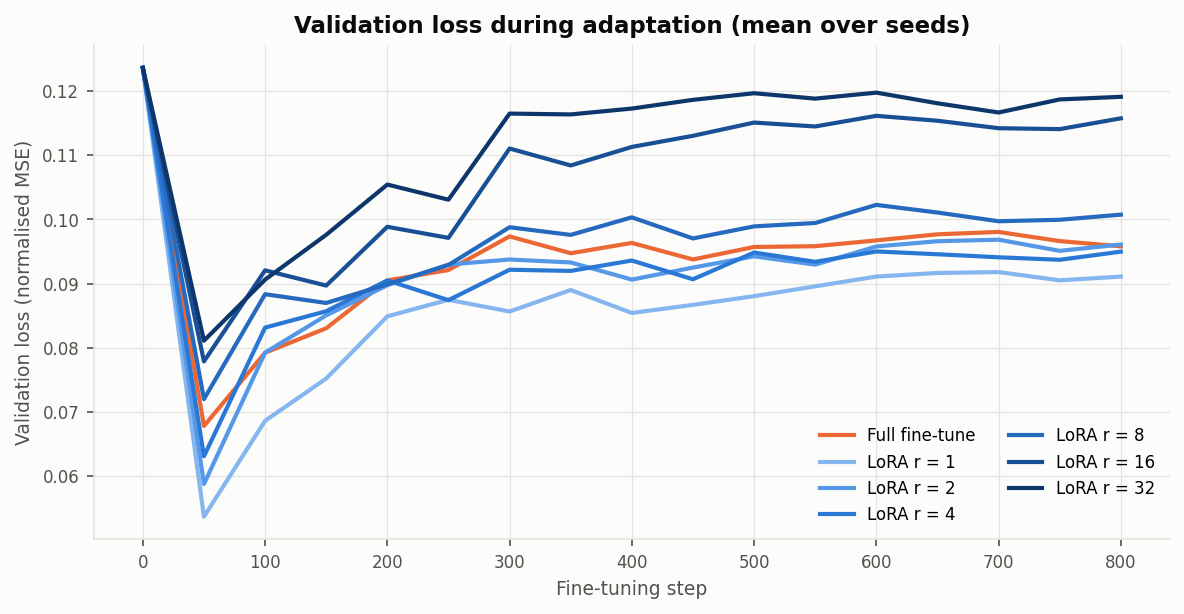

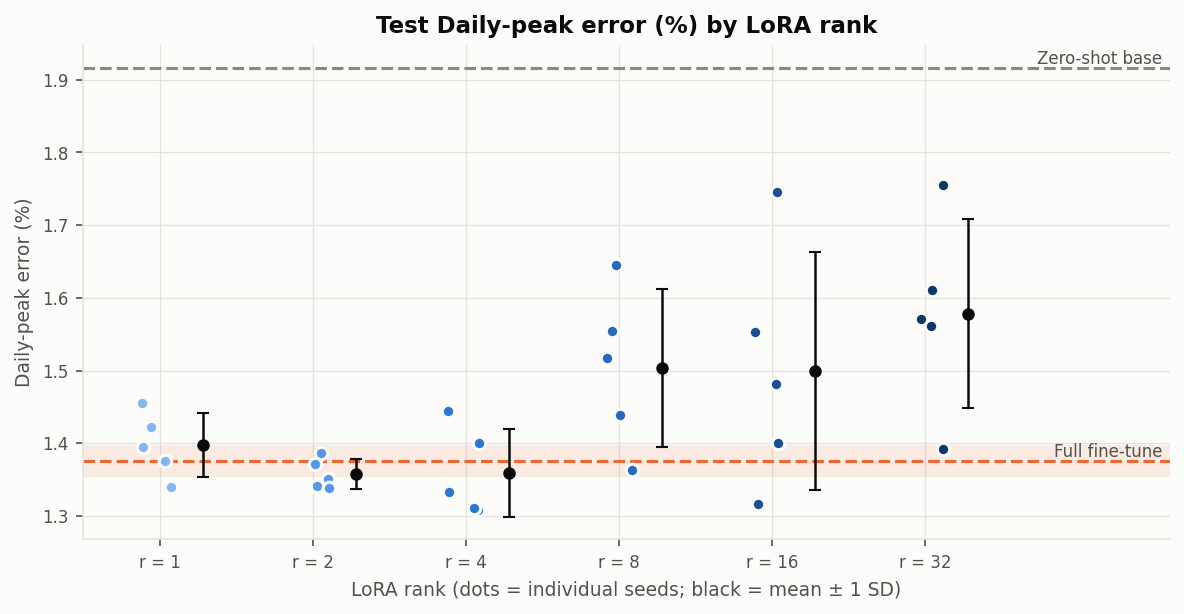

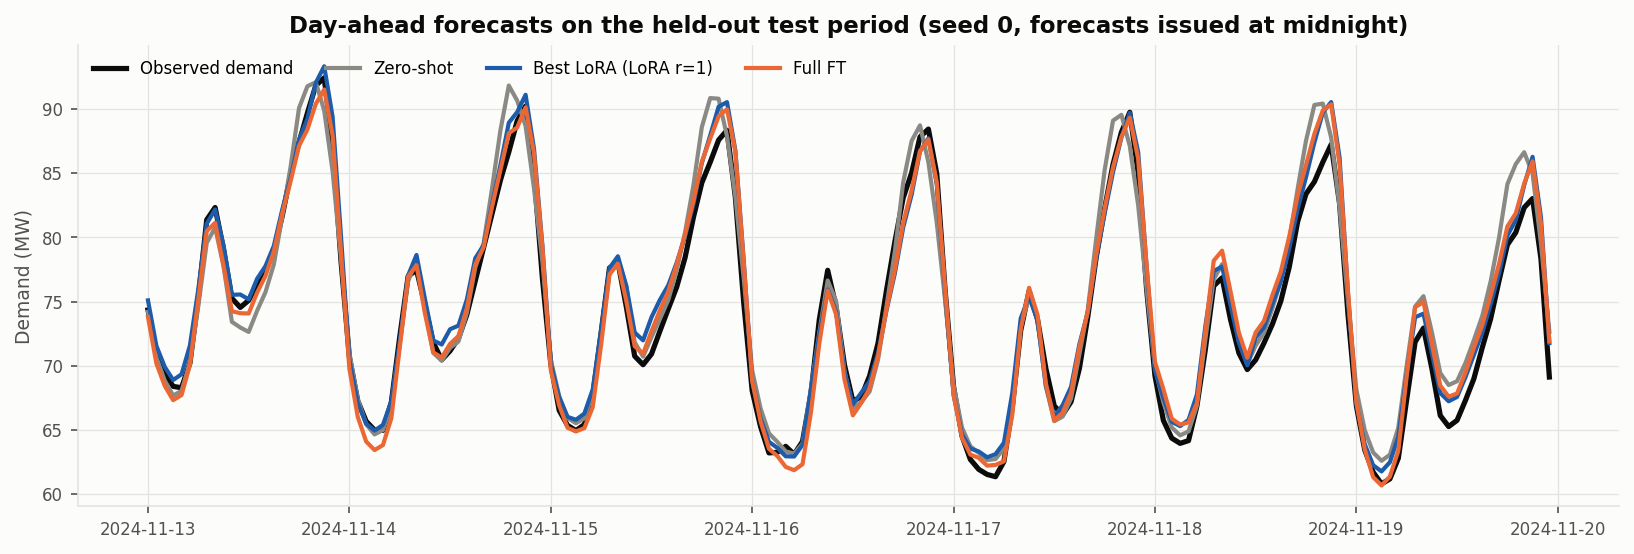

In [8]:
for fig in ["fig_accuracy_vs_rank.png", "fig_pareto.png", "fig_cost_vs_rank.png",
            "fig_learning_curves.png", "fig_peak_error_vs_rank.png", "fig_forecast_example.png"]:
    show(fig)

## 5 · Render the Annex IV-style technical documentation from these results

In [9]:
!python scripts/05_render_report.py --config $CONFIG

wrote docs/Annex_IV_Technical_Documentation.md  (~3,315 words)


## 6 · Bring the results back to the repository
Downloads a zip of `results/` and the rendered document. Unzip it at the repository root locally and commit.

In [10]:
!zip -qr cobalt_results.zip $RESULTS docs/Annex_IV_Technical_Documentation.md data/manifest.json data/data_card.json
from google.colab import files
files.download("cobalt_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>